# Imports & Setup

In [1]:
import torch
import torch.nn as nn
import numpy as np
import time
import sys
import os
import pandas as pd
from datetime import datetime

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(project_root)

from utils.dataset_loader import load_data
from utils.visualize import (plot_loss_and_acc_curve,get_all_preds_and_true,plot_confusion_matrix,plot_classification_report)
from utils.tools import (freeUpMemories, get_optimizer, load_loading_config, load_training_config)

# Config

In [2]:
load_config_id = 8
training_config_id = 2

# Loading Config
config = load_loading_config(load_config_id)
load_method = config['load_method']
window_size = config['window_size']
stride = config['stride']
use_pca = config['use_pca']
use_psd = config['use_psd']
psd_bands = config['psd_bands']
use_psd_pca = config['use_psd_pca']
use_de = config['use_de']
de_bands = config['de_bands']
use_de_pca = config['use_de_pca']
apply_filter = config['apply_filter']
lowcut: float = config['lowcut']
highcut: float = config['highcut']
fs_value: int = config['fs_value']
filter_order = config['filter_order']
apply_baseline = config['apply_baseline']
baseline_window = config['baseline_window']
normalize = config['normalize']
normalization_method = config['normalization_method']

# Training Config
training_config = load_training_config(training_config_id)
random_seed = training_config['random_seed']
np.random.seed(random_seed)
torch.manual_seed(random_seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :",device)
if device.type == "cuda": torch.cuda.set_per_process_memory_fraction(0.9)
apply_train_test_split = training_config['apply_train_test_split']
test_size = training_config['test_size']
epochs = training_config['epochs']
batch_size = training_config['batch_size']
num_classes = training_config['num_classes']
sigmoid_threshold = training_config['sigmoid_threshold']

# Optimizer Config
optimizer_type = training_config['optimizer_type']
learning_rate = training_config['learning_rate']
learning_rate_to_save = training_config['learning_rate_to_save']
weight_decay = training_config['weight_decay']
momentum = training_config['momentum']
betas = training_config['betas']

# Model config
model_name = "CNN_LSTM"
cnn_out_channels: int = 64
lstm_hidden: int = 128
kernel_size = 7
padding = 3
pool_kernel_size = 4
num_layers: int = 2

device : cuda


# Load & Preprocess & Split Data

In [3]:
train_loader, test_loader, ratio, input_size = load_data(load_method,window_size,stride,apply_filter, lowcut,
        highcut, fs_value, filter_order,apply_baseline,baseline_window, normalize, normalization_method,
        apply_train_test_split,test_size,random_seed,batch_size,True,None,None,num_classes,use_psd,psd_bands,
        use_psd_pca,use_de,de_bands,use_de_pca,use_pca,None)

full_path : C:\FACED dataset\Preprocessed_data\pre_XY_win500_str500_low1_high50_fs250_order4_base20_norm_zscore_psd[2, 3]pca_de[1, 2, 3, 4]pca_pca.pkl
file exists , loading ...
Existing Data Shape: (51660, 500, 112) (51660,)
start to binarize labels
y_all classes :  [0 1] Class counts: [27900 23760]
start to train_test_split
start to dataloader creation
returned train_loader, test_loader


# CNN + LSTM Model

In [4]:
try:
    freeUpMemories(model)
except Exception as e:
    freeUpMemories()
    print("error when deleting model :",e)

error when deleting model : name 'model' is not defined


In [ ]:
if num_classes == 2:  
    pos_weight_val = torch.tensor([ratio]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)
elif num_classes == 8:  
    criterion = nn.CrossEntropyLoss()

class CNNLSTM(nn.Module):
    def __init__(self, input_size=input_size, num_classes=num_classes, cnn_out_channels=cnn_out_channels,
                  hidden_size=lstm_hidden,padding=padding):
        super(CNNLSTM, self).__init__()
        
        # 1D CNN: input (B, C_in, T)
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=cnn_out_channels, kernel_size=kernel_size, padding=padding)
        self.bn1 = nn.BatchNorm1d(cnn_out_channels)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=pool_kernel_size)  # Reduce time resolution
        
        # LSTM input will be (B, new_seq_len, cnn_out_channels)
        self.lstm = nn.LSTM(input_size=cnn_out_channels, hidden_size=lstm_hidden,
                            batch_first=True, num_layers=num_layers)
        
        if num_classes == 2:  
            self.output = nn.Linear(hidden_size, 1)
        elif num_classes == 8:  
            self.output = nn.Linear(hidden_size, num_classes)
        else:
            raise ValueError("output_type must be 'binary' or 'multiclass'")

    def forward(self, x):
        # x: (B, T, C) → (B, C, T)
        x = x.permute(0, 2, 1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.pool(x)   # (B, C_out, T//4)

        # (B, C_out, T') → (B, T', C_out) for LSTM
        x = x.permute(0, 2, 1)
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # last hidden state
        return self.output(out)

model = CNNLSTM(input_size,num_classes,cnn_out_channels,lstm_hidden,padding).to(device)
optimizer = get_optimizer(model,optimizer_type,learning_rate,weight_decay,momentum,betas)

In [1]:
# Test Model
x = torch.randn(16, window_size, input_size).to(device)
y = model(x)
if y.shape[0] != 16:
    raise Exception("Model mismatch")


NameError: name 'torch' is not defined

# Training and Evaluation

In [7]:
def train(model, loader, optimizer, criterion, device, num_classes):
    model.train()
    total_loss = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        if num_classes == 2:
            y = y.float().unsqueeze(1)

        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader, device, num_classes,sigmoid_threshold=sigmoid_threshold):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)

            if num_classes == 2:
                preds = torch.sigmoid(out)
                preds = (preds > sigmoid_threshold).int().squeeze()
            else:
                preds = out.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

# Run Training

In [8]:
train_accs, test_accs = [], []
train_losses, test_losses = [], []
epoch_times = []

early_stop_patience = 5
best_loss = float('inf')  
best_accuracy = 0.0
epochs_no_improve = 0
early_stop_triggered = False
best_model_state = None
last_epoch = 0

In [9]:
print("start traning at :",datetime.now().strftime( "%H:%M:%S"))

for epoch in range(1, epochs + 1):
    start_time = time.time()
    
    train_loss = train(model, train_loader, optimizer, criterion, device, num_classes)
    train_acc = evaluate(model, train_loader, device, num_classes,sigmoid_threshold)

    test_loss = 0
    model.eval()
    with torch.no_grad():
        total_loss = 0
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            if num_classes == 2:
                y = y.float().unsqueeze(1)
            out = model(X)
            loss = criterion(out, y)
            total_loss += loss.item()
        test_loss = total_loss / len(test_loader)
    
    test_acc = evaluate(model, test_loader, device, num_classes,sigmoid_threshold)
    
    end_time = time.time()
    epoch_duration = end_time - start_time

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    epoch_times.append(epoch_duration)
    last_epoch = epoch

    print(f"Epoch {epoch}/{epochs} - Time: {epoch_duration:.2f}s - "
        f"Train Loss: {train_loss:.4f} - Test Loss: {test_loss:.4f} - "
        f"Train Acc: {train_acc:.4f} - Test Acc: {test_acc:.4f}")
    
    
	# Early stopping logic
    if test_loss < best_loss - 1e-4:
        best_loss = test_loss
        best_accuracy = test_acc
        epochs_no_improve = 0
        best_model_state = model.state_dict()
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= early_stop_patience:
            print(f"Early stopping triggered at epoch {epoch} ⛔")
            early_stop_triggered = True
            break


start traning at : 05:44:18
Epoch 1/20 - Time: 52.48s - Train Loss: 0.7425 - Test Loss: 0.7390 - Train Acc: 0.5711 - Test Acc: 0.5488
Epoch 2/20 - Time: 40.68s - Train Loss: 0.7286 - Test Loss: 0.7277 - Train Acc: 0.6016 - Test Acc: 0.5633
Epoch 3/20 - Time: 34.44s - Train Loss: 0.7098 - Test Loss: 0.7194 - Train Acc: 0.6349 - Test Acc: 0.5892
Epoch 4/20 - Time: 27.43s - Train Loss: 0.6860 - Test Loss: 0.6959 - Train Acc: 0.6757 - Test Acc: 0.6220
Epoch 5/20 - Time: 29.86s - Train Loss: 0.6560 - Test Loss: 0.6888 - Train Acc: 0.6960 - Test Acc: 0.6285
Epoch 6/20 - Time: 31.73s - Train Loss: 0.6312 - Test Loss: 0.6776 - Train Acc: 0.7291 - Test Acc: 0.6521
Epoch 7/20 - Time: 30.02s - Train Loss: 0.6025 - Test Loss: 0.6709 - Train Acc: 0.7365 - Test Acc: 0.6457
Epoch 8/20 - Time: 32.89s - Train Loss: 0.5773 - Test Loss: 0.6740 - Train Acc: 0.7616 - Test Acc: 0.6610
Epoch 9/20 - Time: 26.59s - Train Loss: 0.5497 - Test Loss: 0.6526 - Train Acc: 0.7881 - Test Acc: 0.6780
Epoch 10/20 - Time

# Plot Results

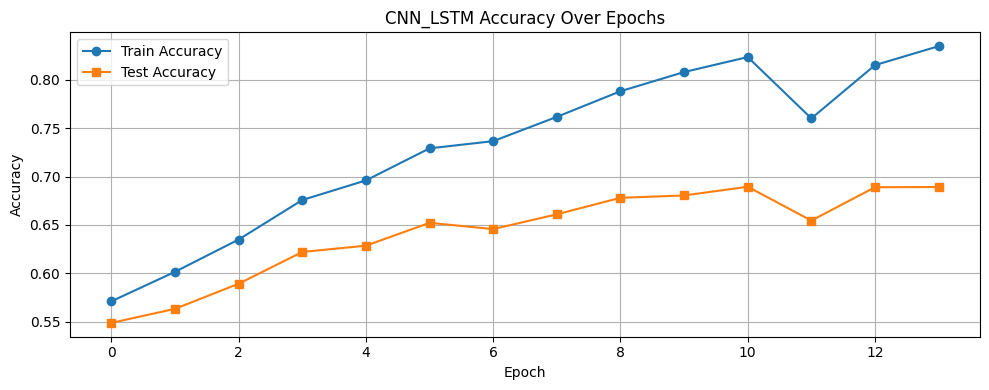

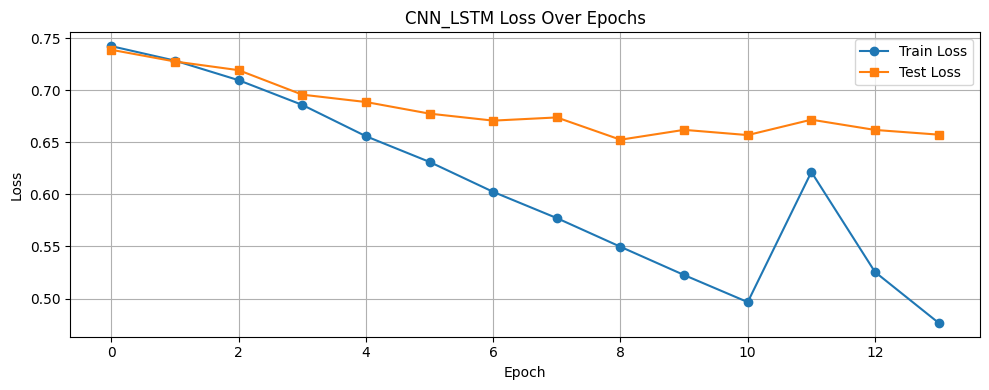

In [10]:
acc_path, loss_path = plot_loss_and_acc_curve(train_accs,test_accs,train_losses,test_losses,model_name)

In [11]:
all_preds, all_trues = get_all_preds_and_true(model,test_loader,device,num_classes,sigmoid_threshold=sigmoid_threshold)

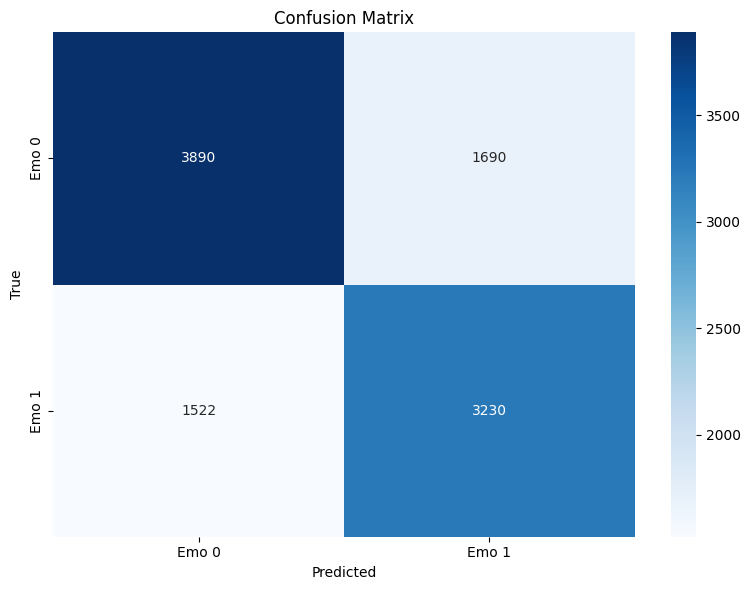

In [12]:
cm_path = plot_confusion_matrix(all_preds,all_trues,num_classes,model_name)

{'0.0': {'precision': 0.7187730968218773, 'recall': 0.6971326164874552, 'f1-score': 0.7077874818049491, 'support': 5580.0}, '1.0': {'precision': 0.6565040650406504, 'recall': 0.6797138047138047, 'f1-score': 0.6679073614557486, 'support': 4752.0}, 'accuracy': 0.689121176926055, 'macro avg': {'precision': 0.6876385809312638, 'recall': 0.6884232106006299, 'f1-score': 0.6878474216303488, 'support': 10332.0}, 'weighted avg': {'precision': 0.6901336815078635, 'recall': 0.689121176926055, 'f1-score': 0.6894454055467802, 'support': 10332.0}}


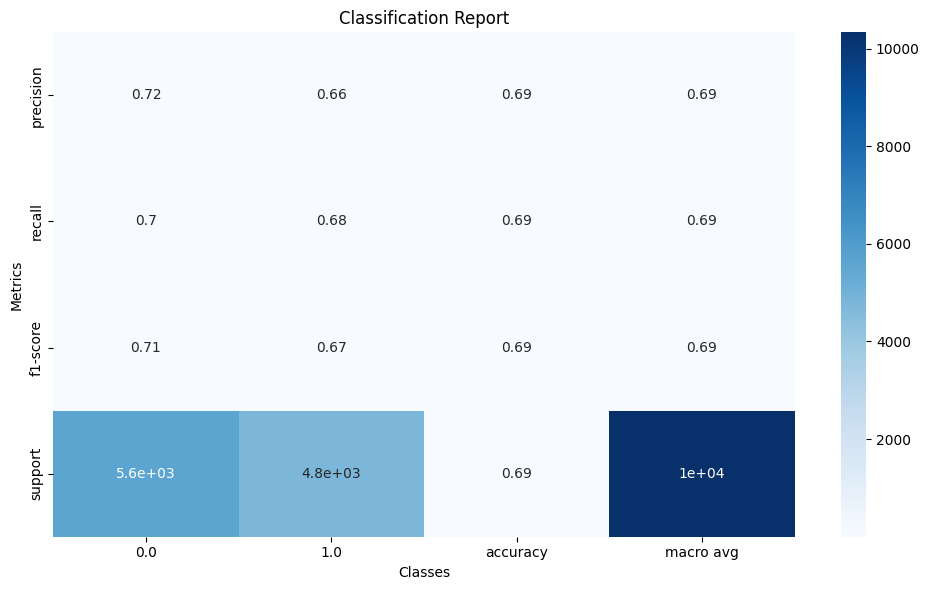

In [13]:
cr_path = plot_classification_report(all_preds,all_trues,model_name)

In [14]:
results_file = "../results/results_summary.xlsx"
sheet_name = model_name

final_train_acc = round(train_accs[-1], 6)
final_test_acc = round(test_accs[-1], 6)
final_train_loss = round(train_losses[-1], 6)
final_test_loss = round(test_losses[-1], 6)
avg_epoch_time = round(sum(epoch_times) / len(epoch_times), 3)

run_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

config_dict = {
    "Timestamp": run_time,
    
	# Load Config
    "Config_Id": str(load_config_id),
	"window_size": str(window_size),
    "strdie": str(stride),
    "use_psd": str(use_psd),
    "use_de": str(use_de),
    "psd_bands": str(psd_bands),
    "use_psd_pca": str(use_psd_pca),
    "de_bands": str(de_bands),
    "use_de_pca": str(use_de_pca),
    "use_pca": str(use_pca),
    
	# Model Config
	"Model": str(model_name),
    "cnn_out_channels": str(cnn_out_channels),
    "Num Layers": str(num_layers),
    "lstm_hidden": str(lstm_hidden),
    "kernel_size": str(kernel_size),
    "padding": str(padding),
    "pool_kernel_size": str(pool_kernel_size),
    
	# Training Config
    "Trainging_Config_Id": str(training_config_id),
    "Epochs": str(epochs),
    "Batch Size": str(batch_size),
    "Optimizer": str(optimizer_type),
    "LR": str(learning_rate_to_save) + " lr",
    "Weight Decay": str(weight_decay),
    "Momentum": str(momentum),
    "Betas": str(betas),
	"Num Classes": str(num_classes),
    "Input Size": str(input_size),
	"Device": str(device),
    "sigmoid_threshold": str(sigmoid_threshold),
    
	# Preprocessing
    "Apply Filter": str(apply_filter),
    "Lowcut": str(lowcut),
    "Highcut": str(highcut),
    "Fs": str(fs_value),
    "Filter Order": str(filter_order),
    "Apply Baseline Correction": str(apply_baseline),
    "Baseline Window": str(baseline_window),
    "Apply Normalization": str(normalize),
    "Normalization Method": str(normalization_method),
	"Test Size": str(test_size),
    "Seed": str(random_seed),
    
	# Results
    "Train Acc": str(final_train_acc),
    "Test Acc": str(final_test_acc),
    "Train Loss": str(final_train_loss),
    "Test Loss": str(final_test_loss),
    "best_loss": str(best_loss),
    "best_acc": str(best_accuracy),
    "Early Stop Trigger": str(early_stop_triggered),
    "last epoch number": str(last_epoch),
	"Avg Epoch Time (s)": str(avg_epoch_time),
    
	# Plots
    "Acc_plot_path": str(acc_path),
    "Loss_plot_path": str(loss_path),
    "CM_plot_path": str(cm_path),
    "CR_plot_path": str(cr_path)
}

df_result = pd.DataFrame([config_dict])

if os.path.exists(results_file):
    with pd.ExcelWriter(results_file, engine='openpyxl', mode='a', if_sheet_exists='overlay') as writer:
        existing_df = pd.read_excel(results_file, sheet_name=sheet_name) if sheet_name in pd.ExcelFile(results_file).sheet_names else pd.DataFrame()
        combined_df = pd.concat([existing_df, df_result], ignore_index=True)
        combined_df.to_excel(writer, index=False, sheet_name=sheet_name,float_format="%.6f")
else:
    with pd.ExcelWriter(results_file, engine='openpyxl') as writer:
        df_result.to_excel(writer, index=False, sheet_name=sheet_name,float_format="%.6f")